# 学生の自転車盗難：いつ・どこで・施錠は？
〜千葉県の2025年データから、高校生・大学生向けの防犯の呼びかけを考える〜

```
    __o
  _ \<_
 (-)/(-)
```

**氏名**
齋藤太知
林崎仁
小林宙音

## 0. 私たちの問い・出典・データの説明

**問い**：自転車を盗まれた被害者のうち、**高校生と大学生**では、被害の起きた**時間帯**と**施錠していなかった割合**にどんな違いがあるか。違いがあれば、防犯の呼びかけは「誰に」「いつ」向けるべきか。

**出典**：千葉県警察 犯罪発生情報（令和7年・自転車盗CSV）
https://www.police.pref.chiba.jp/seisoka/safe-life_publicspace-statistics_00002.html
（2025年分・10,054件、2026年11月18日取得）

**1行が表すもの**：千葉県内で警察が把握した**自転車盗1件**。人数や台数ではなく「件数」です。全15列で、今回使う列は次の4つです。

| 列名 | 中身 | 使い方 |
|---|---|---|
| 被害者の職業 | 高校生・大学生など | 学生グループを選ぶ |
| 施錠関係 | 施錠した／施錠せず | 施錠していなかった割合 |
| 発生時（始期） | 0〜23の時、または不明 | 時間帯別の件数 |
| 市区町村（発生地） | 57の市区町村 | 件数ランキング |

> 緯度・経度の列はないため、地図は作りません。

## 1. CSVを読む

`csv.DictReader` は各行を「列名: 値」の辞書にします。`list` で全行をまとめ、`len` で件数を確認します。文字コードはCP932です（`bike.csv` をNotebookと同じフォルダに置く）。

In [3]:
# 読み込むファイルを設定する（Notebookと同じフォルダに保存）
filename = "bike.csv"
encoding = "cp932"

# 千葉県警のCSVはShift-JIS（CP932）。追加インストールは不要
import csv
with open(filename, encoding=encoding, newline="") as file:
    incidents = list(csv.DictReader(file))

# 1行が1件の事件。件数を確認する
len(incidents)

10054

## 2. 1件の中身と、列の確認

`incidents[0]` は最初の事件の辞書です。今回使う4つの列を取り出して、中身を目で見ておきます。

In [4]:
# 最初の事件から、今回使う4つの列を確認する
row = incidents[0]
print("列の数:", len(row))
for column in ["被害者の職業", "施錠関係", "発生時（始期）", "市区町村（発生地）"]:
    print(f"{column}: {row[column]}")

列の数: 15
被害者の職業: その他
施錠関係: 施錠した
発生時（始期）: 15
市区町村（発生地）: 千葉市中央区


## 3. forで数える①：被害者の職業

「学生」とは、データの **被害者の職業** が高校生・大学生などの件です。まず職業ごとの件数を `for` で数え、**合計が全件数と一致するか**を確かめます。

In [5]:
# 集計したい列を選ぶ
column = "被害者の職業"
counts = {}

# 同じ値が出てくるたびに、件数を1増やす
for row in incidents:
    label = row[column]
    counts[label] = counts.get(label, 0) + 1

# 件数の多い順に表示する
from collections import Counter
for label, count in Counter(counts).most_common():
    print(f"{count:>6,}件  {label}")

# 照合：合計は全件数と一致するか
print("-" * 24)
print(f"{sum(counts.values()):>6,}件  合計（全件数 {len(incidents):,}件）")

 4,983件  その他
 2,192件  高校生
 1,594件  大学生
   950件  中学生
   308件  小学生
    27件  法人・団体、被害者なし
------------------------
10,054件  合計（全件数 10,054件）


## 4. forで数える②：施錠していなかった割合

比べる職業を `groups` に書き、`for` を二重にして「その職業の件数」と「施錠せず・施錠した」を数えます。`groups` を変えて再実行すると、他の職業とも比べられます。

※ここで出る割合は「**盗まれた件のうち**、施錠していなかった件の割合」です。盗まれていない自転車は含まないので、施錠の効果や被害に遭う確率はこの数字からは分かりません。

In [6]:
# 比べる職業を設定する（ここを変えて再実行できる）
groups = ["大学生", "高校生"]

# 職業ごとに、施錠せず・施錠した件数を数える
lock_results = {}
for group in groups:
    total = 0
    unlocked = 0
    locked = 0
    for row in incidents:
        if row["被害者の職業"] == group:
            total += 1
            if row["施錠関係"] == "施錠せず":
                unlocked += 1
            else:
                locked += 1
    lock_results[group] = (total, unlocked, locked)
    print(f"{group}: {total:,}件のうち 施錠せず {unlocked:,}件（{unlocked / total * 100:.1f}%）／施錠した {locked:,}件")

# 比較のため、全体（全職業）も数える
all_unlocked = 0
for row in incidents:
    if row["施錠関係"] == "施錠せず":
        all_unlocked += 1
print(f"全体: {len(incidents):,}件のうち 施錠せず {all_unlocked:,}件（{all_unlocked / len(incidents) * 100:.1f}%）")

大学生: 1,594件のうち 施錠せず 1,084件（68.0%）／施錠した 510件
高校生: 2,192件のうち 施錠せず 1,656件（75.5%）／施錠した 536件
全体: 10,054件のうち 施錠せず 6,879件（68.4%）


## 5. ランキング：市区町村の件数 上位5

`Counter` で市区町村ごとの件数を数え、`most_common(5)` で上位5つを取り出します。`#` 1個＝20件（切り捨て）。正確な件数も必ず添えます。

※件数は人口や駐輪台数で補正した被害率ではありません。「多く報告された地域」であって「危険な地域」とは言えません。

In [7]:
top_n = 5
scale = 20

# 職業ごとに、市区町村の件数を数えて上位を表示する
for group in groups:
    city_counts = Counter()
    for row in incidents:
        if row["被害者の職業"] == group:
            city_counts[row["市区町村（発生地）"]] += 1

    print(f"■ {group}  市区町村 上位{top_n}（# 1個＝{scale}件）")
    for place, count in city_counts.most_common(top_n):
        print(f"{place} ({count:,}件)")
        print("#" * (count // scale))
    print()

■ 大学生  市区町村 上位5（# 1個＝20件）
船橋市 (181件)
#########
習志野市 (165件)
########
千葉市中央区 (150件)
#######
松戸市 (110件)
#####
市川市 (97件)
####

■ 高校生  市区町村 上位5（# 1個＝20件）
船橋市 (224件)
###########
松戸市 (131件)
######
八千代市 (125件)
######
千葉市中央区 (111件)
#####
柏市 (108件)
#####



## 6. forで数える③：時間帯

`発生時（始期）` が数字なら、その時（0〜23）の件数を1増やします。**「不明」は0時に変えず、別に数えて除外**します。

※「始期」は事件の起きた可能性のある時間の**はじめ**です。盗まれた正確な時刻とは限りません。

In [8]:
# 職業ごとに、0〜23時の件数を数える。時刻が不明な事件は別に数える
hours_by_group = {}
unknown_by_group = {}
for group in groups:
    hours = {hour: 0 for hour in range(24)}
    unknown = 0
    for row in incidents:
        if row["被害者の職業"] == group:
            value = row["発生時（始期）"]
            if value.isdigit():
                hours[int(value)] += 1
            else:
                unknown += 1
    hours_by_group[group] = hours
    unknown_by_group[group] = unknown
    print(f"{group}: 時刻あり {sum(hours.values()):,}件／不明 {unknown}件（除外）")

大学生: 時刻あり 1,582件／不明 12件（除外）
高校生: 時刻あり 2,182件／不明 10件（除外）


In [9]:
# 朝（6〜8時）と夕方（16〜18時）の件数を、時刻が分かる件数と比べる
periods = {"朝 6-8時": range(6, 9), "夕方 16-18時": range(16, 19)}

for group in groups:
    known = sum(hours_by_group[group].values())
    for name, hour_range in periods.items():
        count = 0
        for hour in hour_range:
            count += hours_by_group[group][hour]
        print(f"{group} {name}: {count:,}件（時刻が分かる{known:,}件の {count / known * 100:.1f}%）")
    peak_hour = max(hours_by_group[group], key=hours_by_group[group].get)
    print(f"{group} 最多の時間: {peak_hour}時台 {hours_by_group[group][peak_hour]:,}件")
    print()

大学生 朝 6-8時: 237件（時刻が分かる1,582件の 15.0%）
大学生 夕方 16-18時: 366件（時刻が分かる1,582件の 23.1%）
大学生 最多の時間: 17時台 150件

高校生 朝 6-8時: 671件（時刻が分かる2,182件の 30.8%）
高校生 夕方 16-18時: 538件（時刻が分かる2,182件の 24.7%）
高校生 最多の時間: 7時台 401件



## 7. グラフ：時間帯別の件数

同じデータを棒グラフにします。グラフの文字は、環境ごとの日本語フォントの問題を避けるため英語です。高校生は朝に、大学生は夕方に山があるかを見ます。

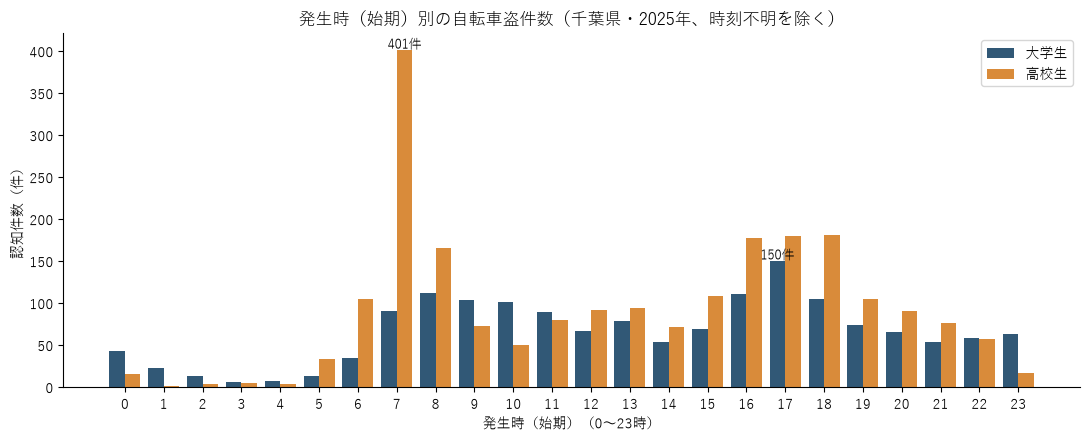

In [10]:
import matplotlib.pyplot as plt

# 日本語フォントの候補（先に見つかったものが使われる）
plt.rcParams["font.sans-serif"] = [
    "Yu Gothic", "Meiryo", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic",
]

colors = {"大学生": "#315876", "高校生": "#d98b3a"}
width = 0.4

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, group in enumerate(groups):
    xs = []
    ys = []
    for hour in range(24):
        xs.append(hour + (i - 0.5) * width)
        ys.append(hours_by_group[group][hour])
    ax.bar(xs, ys, width=width, label=group, color=colors[group])

    # 最多の時間に、正確な件数を書く
    peak_hour = max(hours_by_group[group], key=hours_by_group[group].get)
    peak_count = hours_by_group[group][peak_hour]
    ax.annotate(f"{peak_count:,}件", (peak_hour + (i - 0.5) * width, peak_count),
                ha="center", va="bottom", fontsize=9)

ax.set_xticks(range(24))
ax.set_xlabel("発生時（始期）（0〜23時）")
ax.set_ylabel("認知件数（件）")
ax.set_title("発生時（始期）別の自転車盗件数（千葉県・2025年、時刻不明を除く）")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 8. 確かめたこと（照合）

数えた結果が元データと合っているかを、コードで確認します。

In [11]:
# 照合1：施錠せず＋施錠した ＝ その職業の件数
# 照合2：時刻あり＋不明 ＝ その職業の件数
# 照合3：市区町村の件数の合計 ＝ その職業の件数
for group in groups:
    total, unlocked, locked = lock_results[group]
    known = sum(hours_by_group[group].values())
    unknown = unknown_by_group[group]

    city_total = 0
    for row in incidents:
        if row["被害者の職業"] == group:
            city_total += 1

    print(f"{group}: 件数 {total:,}")
    print("  施錠せず+施錠した =", unlocked + locked, "→", unlocked + locked == total)
    print("  時刻あり+不明     =", known + unknown, "→", known + unknown == total)
    print("  元データの再カウント =", city_total, "→", city_total == total)

# 施錠関係の値は2種類だけか
values = set()
for row in incidents:
    values.add(row["施錠関係"])
print("施錠関係の値:", values)

# 元データの数行を、目で見て確かめる（高校生・7時台の最初の3件。CSVでは「07」のように0が付く）
shown = 0
for row in incidents:
    if row["被害者の職業"] == "高校生" and row["発生時（始期）"].isdigit() and int(row["発生時（始期）"]) == 7:
        print(row["市区町村（発生地）"], row["発生年月日（始期）"], row["発生時（始期）"], row["施錠関係"])
        shown += 1
        if shown == 3:
            break

大学生: 件数 1,594
  施錠せず+施錠した = 1594 → True
  時刻あり+不明     = 1594 → True
  元データの再カウント = 1594 → True
高校生: 件数 2,192
  施錠せず+施錠した = 2192 → True
  時刻あり+不明     = 2192 → True
  元データの再カウント = 2192 → True
施錠関係の値: {'施錠せず', '施錠した'}
千葉市中央区 2025-07-14 07 施錠した
千葉市中央区 2025-05-03 07 施錠した
千葉市中央区 2025-09-03 07 施錠せず


## 9. 数値からの発見と防犯の提案

### 発見1：高校生は「施錠せず」の割合が高い
- 高校生は **2,192件のうち1,656件（75.5%）** が施錠していなかった。
- 大学生は **1,594件のうち1,084件（68.0%）**。全体は **10,054件のうち6,879件（68.4%）**。
- 高校生は、大学生や全体より約7ポイント高い。

### 発見2：被害の山の時間帯が、高校生と大学生で違う
- 高校生は **6〜8時に671件（時刻が分かる2,182件の30.8%）**。7時台だけで **401件（18.4%）** と、1日で最多。
- 大学生は **16〜18時に366件（時刻が分かる1,582件の23.1%）** で、17時台が **150件** と最多。大学生の朝（6〜8時）は237件（15.0%）。

### 発見3：件数の多い市区町村は、学生の種類で少し違う
- 高校生の1位は船橋市（224件）、2位は松戸市（131件）。大学生は1位が船橋市（181件）、2位が **習志野市（165件）**。
- 習志野市は大学生では2位だが、高校生の上位5には入らない。ただし件数は被害率ではなく、人口や学生数の違いも含む。

### 防犯の提案：「とめたら、すぐカギ」を学生の時間帯に合わせて呼びかける
1. **高校生向け**：登校時間帯（7時前後）に、駅や学校の駐輪場で「着いたらすぐカギ」のポスターや声かけをする。施錠せずの割合が75.5%と高いため、まずは「必ず鍵をかける」を伝える。
2. **大学生向け**：夕方（16〜18時）の前に、キャンパスの駐輪場で「授業の前にカギを確認」と呼びかける。大学生は夕方に山があるので、昼間にとめたままの自転車に注意を促す。
3. 件数の多い船橋市・習志野市・松戸市の駅前や大学周辺から、試験的に始める。

> 7時台の山は、盗まれた時刻ではなく「自転車をとめた時刻」に近い可能性があります。その場合も、朝にとめるとき施錠する呼びかけは意味を持ちますが、データだけでは断定できません。

## 10. 限界・注意

- **件数であって被害率ではない**：人口、学生数、駐輪台数などの分母がないため、「盗まれやすさ」や「施錠の効果」は計算していません。
- **施錠せず＝盗まれた件の中での割合**：盗まれなかった自転車の施錠率は不明です。
- **除外した件**：時刻が不明な件は、高校生10件・大学生12件を時間帯の集計から除外しました（全体では日付不明76件、時刻不明103件）。
- **「学生」の範囲**：被害者の職業が高校生・大学生の件だけを比べました（中学生・小学生は含みません）。
- **始期の意味**：「発生時（始期）」は正確な盗難時刻とは限りません。
- 緯度・経度がないため、地図は作らず、市区町村の集計だけを示しました。